# Oppgave 2 – Klorofyll-a-kart (HYPSO-2 vs. Sentinel-3 OLCI)

Steg:
1. Les inn `chlor_a(oci)` + lat/lon fra begge filene
2. Masker ugyldige piksler (land, sky, flagg)
3. Beskjær Sentinel-3 til området HYPSO-2 dekker
4. Plott begge kartene side ved side i samme projeksjon og med felles fargeskala
5. Enkel statistikk til tolkningen

In [1]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.path import Path
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning, module="shapely")  # ufarlige cartopy-advarsler

# Filnavn
FIL_H2 = "HYPSO2_HSI_aeronetvenice_2025-05-14T10-45-06Z-l1d_L2_OCSMART.h5"
FIL_S3 = "S3B_OL_1_EFR____20250514T091545_20250514T091845_20250515T101142_0179_106_264_2160_ESA_O_NT_004_L2_OCSMART.h5"

# Felles fargeskala for Chl-a [mg m^-3] (log-skala)
VMIN, VMAX = 0.1, 30

## 1. Les inn data

In [2]:
def les_produkt(filnavn, variabel):
    """Leser lat, lon, et produkt (f.eks. chlor_a(oci)) og L2-flaggene fra en OC-SMART-fil."""
    with h5py.File(filnavn, "r") as f:
        lat = f["Latitude"][:]
        lon = f["Longitude"][:]
        data = f[variabel][:]
        flagg = f["L2_flags"][:]
    return lat, lon, data, flagg

lat_h2, lon_h2, chl_h2, flagg_h2 = les_produkt(FIL_H2, "chlor_a(oci)")
lat_s3, lon_s3, chl_s3, flagg_s3 = les_produkt(FIL_S3, "chlor_a(oci)")

print("HYPSO-2 :", chl_h2.shape)
print("Sentinel-3:", chl_s3.shape)

HYPSO-2 : (598, 1092)
Sentinel-3: (4091, 4865)


## 2. Masker ugyldige piksler

Land/sky er allerede NaN i dataene. I tillegg beholder vi bare piksler med `L2_flags == 0`
(flagg 256 har verdier, men er flagget som usikre). Urimelige verdier fjernes også.

In [3]:
def masker(data, flagg, kun_flagg_0=True, maks=100):
    """Setter ugyldige piksler til NaN."""
    data = data.copy()
    ugyldig = ~np.isfinite(data) | (data <= 0) | (data > maks)  # NaN, negative og ekstreme verdier
    if kun_flagg_0:
        ugyldig |= flagg != 0                                    # flaggede piksler
    data[ugyldig] = np.nan
    return data

chl_h2 = masker(chl_h2, flagg_h2)
chl_s3 = masker(chl_s3, flagg_s3)

print(f"Gyldige piksler HYPSO-2:    {np.isfinite(chl_h2).sum()}")
print(f"Gyldige piksler Sentinel-3: {np.isfinite(chl_s3).sum()}")

Gyldige piksler HYPSO-2:    122249
Gyldige piksler Sentinel-3: 2581978


## 3. Beskjær Sentinel-3 til HYPSO-2-området

HYPSO-2-sporet ligger skrått, så vi bruker **omrisset** av HYPSO-bildet (kantene i lat/lon-gridet)
som en polygon, og beholder bare Sentinel-3-pikslene som ligger inni den.

In [4]:
# Omriss av HYPSO-2-bildet: gå rundt alle fire kantene av lat/lon-gridet
kant_lon = np.concatenate([lon_h2[0, :], lon_h2[:, -1], lon_h2[-1, ::-1], lon_h2[::-1, 0]])
kant_lat = np.concatenate([lat_h2[0, :], lat_h2[:, -1], lat_h2[-1, ::-1], lat_h2[::-1, 0]])
hypso_omriss = Path(np.column_stack([kant_lon, kant_lat]))

# Først grov beskjæring med en boks (raskere), så nøyaktig test mot polygonet
boks = ((lat_s3 >= kant_lat.min()) & (lat_s3 <= kant_lat.max()) &
        (lon_s3 >= kant_lon.min()) & (lon_s3 <= kant_lon.max()))
rader = np.where(boks.any(axis=1))[0]
kol = np.where(boks.any(axis=0))[0]
lat_s3c = lat_s3[rader.min():rader.max() + 1, kol.min():kol.max() + 1]
lon_s3c = lon_s3[rader.min():rader.max() + 1, kol.min():kol.max() + 1]
chl_s3c = chl_s3[rader.min():rader.max() + 1, kol.min():kol.max() + 1].copy()

# Sett alt utenfor HYPSO-omrisset til NaN
inni = hypso_omriss.contains_points(np.column_stack([lon_s3c.ravel(), lat_s3c.ravel()]))
chl_s3c[~inni.reshape(chl_s3c.shape)] = np.nan

print("Beskåret Sentinel-3:", chl_s3c.shape)

Beskåret Sentinel-3: (2018, 1521)


## 4. Kart side ved side

- Projeksjon: UTM sone 33N (EPSG:32633), samme for begge
- Felles log-fargeskala `VMIN`–`VMAX`
- Samme kartutsnitt (havområdet i HYPSO-2-scenen) i begge panelene
- Grått = ingen gyldige data, stiplet linje = omrisset av HYPSO-2-bildet

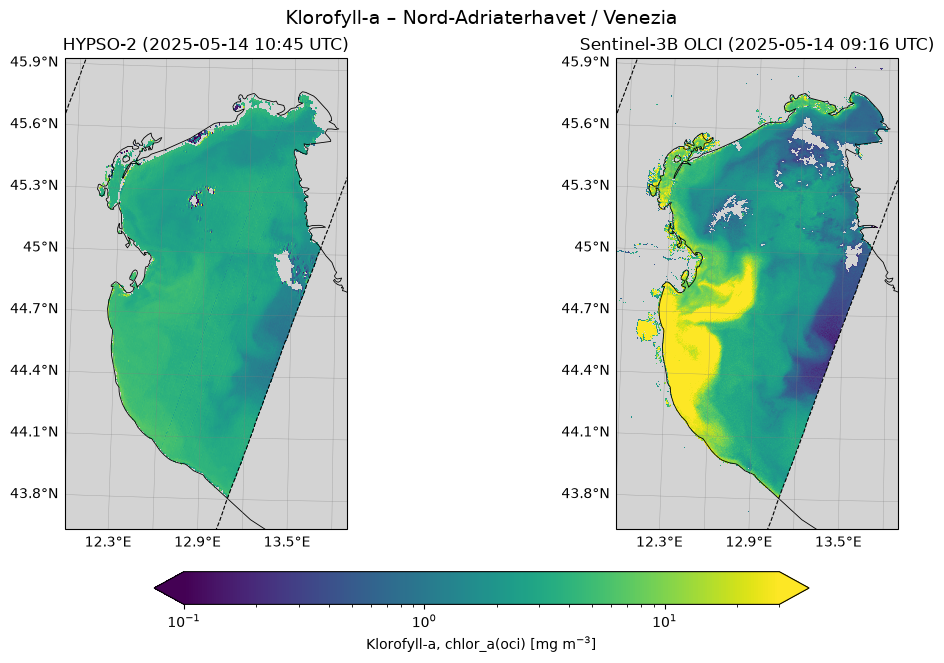

In [5]:
proj = ccrs.UTM(zone=33)          # kartprojeksjon (CRS) for plottet
data_crs = ccrs.PlateCarree()     # dataene er i vanlige lat/lon-grader
norm = LogNorm(vmin=VMIN, vmax=VMAX)
# Kartutsnitt: zoom inn på havområdet med gyldige HYPSO-data (+ litt marg)
gyldig = np.isfinite(chl_h2)
marg = 0.15
utsnitt = [lon_h2[gyldig].min() - marg, lon_h2[gyldig].max() + marg,
           lat_h2[gyldig].min() - marg, lat_h2[gyldig].max() + marg]

fig, akser = plt.subplots(1, 2, figsize=(11, 6.5), subplot_kw={"projection": proj},
                          constrained_layout=True)

for ax, lon, lat, chl, tittel in [
    (akser[0], lon_h2, lat_h2, chl_h2, "HYPSO-2 (2025-05-14 10:45 UTC)"),
    (akser[1], lon_s3c, lat_s3c, chl_s3c, "Sentinel-3B OLCI (2025-05-14 09:16 UTC)"),
]:
    bilde = ax.pcolormesh(lon, lat, chl, transform=data_crs, norm=norm,
                          cmap="viridis", shading="auto")
    ax.plot(kant_lon, kant_lat, transform=data_crs, color="k", lw=0.8, ls="--")  # HYPSO-omriss
    ax.set_facecolor("lightgray")  # grått = ingen data (land, sky, utenfor sporet)
    ax.add_feature(cfeature.COASTLINE.with_scale("10m"), linewidth=0.6)
    ax.set_extent(utsnitt, crs=data_crs)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.6)
    gl.top_labels = gl.right_labels = False
    ax.set_title(tittel)

# Én felles fargebar med enhet
cbar = fig.colorbar(bilde, ax=akser, orientation="horizontal", shrink=0.6, pad=0.04, extend="both")
cbar.set_label("Klorofyll-a, chlor_a(oci) [mg m$^{-3}$]")

fig.suptitle("Klorofyll-a – Nord-Adriaterhavet / Venezia", fontsize=14)
fig.savefig("oppgave2_chla_kart.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Statistikk (hjelp til tolkningen)

Sammenligner fordelingen av Chl-a innenfor samme område for de to sensorene.

HYPSO-2      n= 122249  median= 3.21  5%= 1.38  95%= 4.95  snitt= 3.24 mg m^-3
Sentinel-3   n= 219264  median= 2.49  5%= 0.44  95%=42.79  snitt= 7.86 mg m^-3


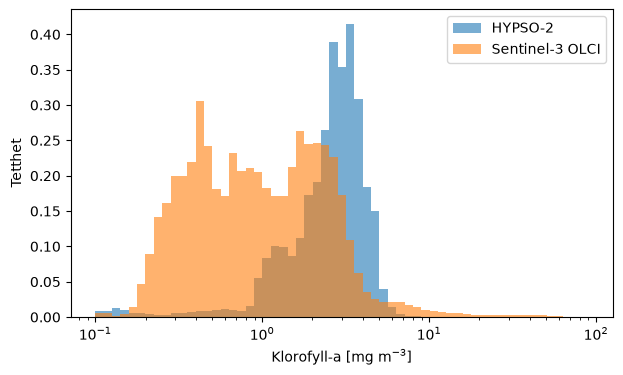

In [6]:
def stats(navn, chl):
    v = chl[np.isfinite(chl)]
    p5, p50, p95 = np.percentile(v, [5, 50, 95])
    print(f"{navn:12s} n={v.size:7d}  median={p50:5.2f}  5%={p5:5.2f}  95%={p95:5.2f}  "
          f"snitt={v.mean():5.2f} mg m^-3")

stats("HYPSO-2", chl_h2)
stats("Sentinel-3", chl_s3c)

# Histogram på log-skala
bins = np.logspace(np.log10(VMIN), np.log10(VMAX * 3), 60)
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(chl_h2[np.isfinite(chl_h2)], bins=bins, density=True, alpha=0.6, label="HYPSO-2")
ax.hist(chl_s3c[np.isfinite(chl_s3c)], bins=bins, density=True, alpha=0.6, label="Sentinel-3 OLCI")
ax.set_xscale("log")
ax.set_xlabel("Klorofyll-a [mg m$^{-3}$]")
ax.set_ylabel("Tetthet")
ax.legend()
plt.show()

## Answers for the report (Task 2)

Both maps use a common logarithmic colour scale of 0.1–30 mg m⁻³.
This range covers both the oligotrophic central Adriatic and the eutrophic Po plume, and a log scale suits the approximately log-normal distribution of Chl-a.
OLCI was cropped to the HYPSO-2 footprint (dashed outline), and only unflagged pixels are shown.

**Similarities.** Both sensors show the same large-scale pattern.
Chl-a is high along the Italian coast and around the Po delta and decreases towards the south-east and the central Adriatic.
The fronts and filaments are in the same positions, and the median Chl-a in the common area is similar (HYPSO-2: 3.2 mg m⁻³, OLCI: 2.5 mg m⁻³).

**Differences.** The dynamic range differs strongly.
For HYPSO-2, 90 % of the pixels lie between 1.4 and 5.0 mg m⁻³; for OLCI the range is 0.4 to 43 mg m⁻³.
OLCI shows a pronounced Po plume (>30 mg m⁻³), where HYPSO-2 gives only about 4–5 mg m⁻³.
In the clearest water OLCI gives 0.2–0.4 mg m⁻³, while HYPSO-2 stays near 1 mg m⁻³.
The cloud masks also differ.

**Possible causes.**
(1) The OCI algorithm is driven by the blue/green Rrs ratio. At the same locations, HYPSO-2 has much higher blue Rrs in turbid water and a flatter spectrum in clear water. Its ratio therefore varies less, and the Chl-a range is compressed (see Task 3). Likely reasons are calibration and atmospheric-correction errors and a lower signal-to-noise ratio in the blue.
(2) OCI was developed for open-ocean water (O'Reilly et al., 1998; Hu et al., 2012). In the plume, CDOM and sediment absorption in the blue are interpreted as chlorophyll, so OLCI probably overestimates Chl-a there.
(3) The images were acquired 1.5 h apart (OLCI 09:16 UTC, HYPSO-2 10:45 UTC), so fronts may have moved.
(4) The sensors have different spatial and spectral resolution: OLCI has about 300 m pixels and 10 nm bands, while HYPSO-2 has narrow bands and pixels of about 140 × 900 m in this product.